# От локальных правил к дендритам

## Компьютерное моделирование роста кристалла: диффузия, поверхностная кинетика и геометрия среды

**МГТУ им. Н. Э. Баумана**  
Факультет «Специальное машиностроение» · кафедра СМ-6  
Дисциплина: «Компьютерное моделирование» · домашнее задание

**Выполнили:** Д. М. Брюшков, СМ6-92; М. А. Шихин, СМ6-93.  
**Преподаватель:** В. А. Федулов.  
*Реквизиты перенесены из титульного листа исходной работы; подписи не воспроизводились.*

---

> **Главный вопрос:** почему одинаковые частицы на одной решётке образуют то плотную колонию, то ажурный дендрит, то структуру, растущую против потока?
>
> **Масштаб исследования:** 7 вариантов модели · 10 реализаций каждого · 4 000 частиц в каждой реализации · 70 расчётов.
>
> **Ключевой результат:** при снижении вероятности прилипания с 1 до 0,15 средний радиус инерции уменьшается на **25,7%**, а заполнение охватывающего диска увеличивается в **1,76 раза**. Эти числа рассчитаны по ансамблям, а не выбраны по удачной картинке.

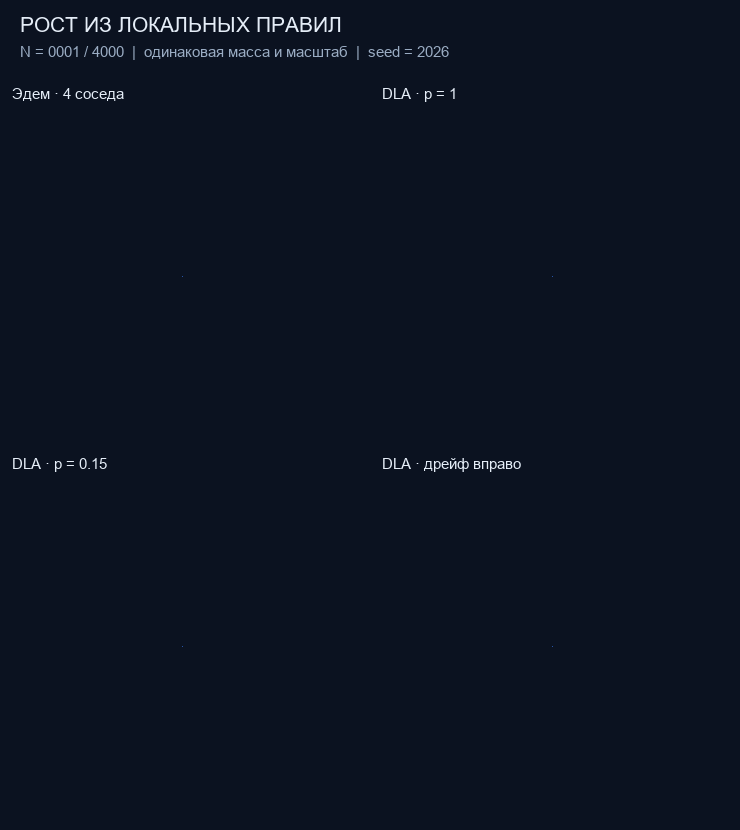

*Рисунок 1. Сравнение Эдема, DLA, DLA с неполным прилипанием и DLA с дрейфом. Цвет обозначает порядок присоединения: синий → бирюзовый → золотой. Каждый кадр соответствует одинаковому числу занятых клеток, а не одинаковому физическому времени. Масштаб панелей одинаков; seed = 2026. Если просмотрщик не воспроизводит GIF, откройте [файл отдельно](results/growth.gif).*



### Содержание

1. [Постановка задачи и развитие исходной работы](#1-постановка-задачи-и-развитие-исходной-работы)
2. [Математическая модель](#2-математическая-модель)
3. [План экспериментов и воспроизводимость](#3-план-экспериментов-и-воспроизводимость)
4. [Измеряемые характеристики](#4-измеряемые-характеристики)
5. [Результаты и обсуждение](#5-результаты-и-обсуждение)
6. [Проверка реализации](#6-проверка-реализации)
7. [Ограничения исследования](#7-ограничения-исследования)
8. [Заключение](#8-заключение)
9. [Источники и состав материалов](#9-источники-и-состав-материалов)

---



<a id="1-постановка-задачи-и-развитие-исходной-работы"></a>

## 1. Постановка задачи и развитие исходной работы



### Цель

Исследовать, как механизм доставки частиц, вероятность их закрепления, окрестность и свойства препятствия влияют на геометрию растущего кристалла. Перейти от качественной демонстрации к проверяемому вычислительному эксперименту.

В исходной работе уже сравнивались DLA и модель Эдема, окрестности фон Неймана и Мура, а также рост рядом с кольцевым препятствием. Расширенная версия сохраняет эту тему, но усложняет физические правила и усиливает методику измерений.

| Было в исходной версии | Сделано в расширенной версии |
|---|---|
| По одному случайному изображению | По 10 воспроизводимых реализаций каждого варианта |
| Фиксированное число попыток роста | Ровно 4 000 занятых клеток, включая затравку |
| Приблизительная ось числа частиц | Точная история присоединений каждой клетки |
| Радиус с добавочным отступом для запуска | Радиус инерции без искусственных добавок |
| Повторяющиеся клетки в списке границы Эдема | Каждая свободная граничная клетка учитывается один раз |
| Стенка одновременно названа препятствием и центром прилипания | Раздельные отражающая и нуклеирующая стенки |
| Ожидаемая размерность в подписи рисунка | Измеренный эффективный показатель и ограничения его интерпретации |
| Две базовые модели | Дополнительно неполное прилипание и направленный перенос |

Новая реализация вынесена в отдельную папку, поскольку точечная правка старых рисунков не исправила бы экспериментальный протокол. После завершения новой версии старые материалы удалены из рабочей папки по запросу пользователя. Проверенная резервная копия сохранена рядом с папкой ДЗ: `../../Архив_старого_ДЗ_20261123_175818.zip`. Файл `../Кристалл.tex` полностью переоформлен по новому исследованию; `../Кристалл.pdf` содержит актуальный печатный отчёт.



### Проверяемые гипотезы

- **H1.** При одинаковой массе DLA образует более разреженный и протяжённый кластер, чем модель Эдема.
- **H2.** Уменьшение вероятности прилипания позволяет частицам исследовать более глубокие участки границы и повышает компактность.
- **H3.** Дрейф нарушает симметрию доставки частиц, но направление роста не обязано совпадать с направлением их движения.
- **H4.** Непроницаемая стенка и поверхность, на которой зарождается кристалл, дают качественно разные результаты даже при одинаковой геометрии.
- **H5.** Окрестность Мура меняет структуру фронта Эдема; утверждение о её большей изотропности необходимо проверять, а не принимать заранее.



<a id="2-математическая-модель"></a>

## 2. Математическая модель



### 2.1. Класс модели и состояние системы

Используется квадратная решётка

$$A=\{0,\ldots,L-1\}^2,\qquad L=501.$$

Физическое состояние клетки:

$$s_{ij}\in\{0,1,2\},$$

где 0 — свободное пространство, 1 — кристалл, 2 — неподвижная стенка. В коде препятствия хранятся отдельной булевой маской, а положительное значение `birth[i,j]` — это номер присоединения клетки к кристаллу. Такая запись одновременно задаёт занятость и позволяет восстановить любой кадр без повторного расчёта.

Начальное состояние: одна клетка кристалла в центре $(250,250)$. В опытах с препятствием добавляется кольцо.

**Важное уточнение терминологии.** Это стохастические асинхронные решёточные модели роста, а не классический детерминированный КА с синхронным обновлением всех клеток. В DLA полное состояние включает также координаты подвижной частицы и состояние генератора случайных чисел. Одна матрица занятости не определяет следующий шаг. Локальность взаимодействий и дискретное пространство связывают модель с темой клеточных автоматов, но не делают эти определения тождественными.



### 2.2. Модель Эдема

Пусть $B_t$ — множество свободных клеток, имеющих хотя бы одного соседа-кристалл. На каждом шаге одна клетка равновероятно выбирается из **уникальных** элементов $B_t$ и присоединяется к кластеру:

$$P(q\text{ будет выбрана})=\frac{1}{|B_t|}.$$

Исследуются окрестности:

- **фон Неймана:** четыре ортогональных соседа;
- **Мура:** восемь соседей, включая диагональные.

Выбор клетки с несколькими занятыми соседями не получает дополнительного веса. Это существенно: список с дубликатами реализовал бы другой вариант роста. После каждого присоединения выбранная клетка удаляется из границы, а новые доступные клетки добавляются без повторений.

Параметр времени здесь — число добавленных клеток. При фиксированной массе обе окрестности имеют одинаковое число событий роста; по этому эксперименту нельзя заключить, что одна из них «быстрее заполняет пространство за итерацию».



### 2.3. Диффузионно-ограниченная агрегация, DLA

Одна частица запускается на окружности вокруг центральной затравки. Её угол выбирается равномерно. Радиус запуска зависит от текущего максимального расстояния кристалла от затравки:

$$R_{\mathrm{launch}}=R_{\max}+10.$$

В опытах с кольцом дополнительно требуется $R_{\mathrm{launch}}\geq36$, чтобы источник находился снаружи стенки. Непрерывные координаты окружности округляются до узлов решётки.

Частица совершает случайные шаги по четырём направлениям. При наличии ортогонального соседа-кристалла она закрепляется с вероятностью $p$. При отказе следует очередная попытка перемещения; шаги внутрь кристалла и стенки отклоняются, и частица остаётся на месте.

- Базовая DLA: $p=1$.
- Модель с ограниченной поверхностной кинетикой: $p=0{,}15$.

Вероятность $p$ проверяется при каждом посещении контактной позиции, а не один раз за всю траекторию. Поэтому $p=0{,}15$ не означает, что закрепится ровно 15% запущенных частиц.

Далеко ушедшая частица удаляется; вместо неё запускается новая:

$$R_{\mathrm{kill}}=\min(2R_{\mathrm{launch}},\lfloor L/2\rfloor-2).$$

Одна траектория ограничена 100 000 шагами. Удалённые и остановленные по лимиту частицы **не увеличивают массу**. Расчёт заканчивается только при достижении $N=4\,000$ либо явной ошибкой лимита/размера поля. Периодические границы не используются; пересечения внешней окружности поглощают частицу.



### 2.4. Направленный перенос

В варианте с дрейфом $b=0{,}35$ вероятности шагов равны

$$P(\rightarrow)=\frac{1+b}{4}=0{,}3375,\qquad
P(\leftarrow)=\frac{1-b}{4}=0{,}1625,$$

$$P(\uparrow)=P(\downarrow)=\frac14.$$

Среднее свободное смещение за шаг:

$$\mathbb E[\Delta x]=b/2=0{,}175.$$

Таким образом, частицы переносятся вправо. Это параметр транспортного правила, а не заданное направление роста кристалла.



### 2.5. Кольцевая камера

Относительно затравки вычисляются расстояние $r$ и полярный угол $\theta$. Стенка занимает клетки

$$24\leq r\leq26,\qquad |\theta|\geq\pi/6.$$

Справа остаётся разрыв с углом 60°. Во всех опытах стенка непроницаема и не изменяется.

1. **Отражающая стенка.** Закрепление возможно только рядом с существующим кристаллом. Частице необходимо попасть через разрыв к затравке; ветви затем могут выйти наружу через ту же щель.
2. **Стенка с нуклеацией.** Закрепление разрешено также рядом со стенкой. На её поверхности возникают дополнительные участки кристалла, первоначально не связанные с центральной затравкой.

Вторая модель — не просто препятствие, а идеализированная активная подложка. Смешение этих двух правил привело бы к неверному объяснению результатов.



<a id="3-план-экспериментов-и-воспроизводимость"></a>

## 3. План экспериментов и воспроизводимость

| Код | Механизм | Окрестность | $p$ | $b$ | Стенка |
|---|---|---:|---:|---:|---|
| `eden4` | Эдем | 4 | — | — | Нет |
| `eden8` | Эдем | 8 | — | — | Нет |
| `dla` | DLA | 4 | 1 | 0 | Нет |
| `slow` | DLA | 4 | 0,15 | 0 | Нет |
| `drift` | DLA | 4 | 1 | 0,35 | Нет |
| `reflect` | DLA | 4 | 1 | 0 | Отражение |
| `catalytic` | DLA | 4 | 1 | 0 | Нуклеация |

Общие условия: поле **501 × 501**, масса **4 000**, одна центральная затравка. По 10 реализаций с целочисленными seed **2026–2035**. Отдельный генератор заново инициализируется для каждого расчёта. Совпадение seed между моделями не означает совпадения траекторий: алгоритмы потребляют случайные числа по-разному.

Для иллюстраций заранее выбран первый seed, **2026**. Выводы сделаны по всем десяти реализациям, включая менее симметричные.

Для каждой характеристики приведены среднее и приближённый 95%-й доверительный t-интервал среднего:

$$\overline x\;\pm\;t_{0.975,9}\frac{s}{\sqrt{10}},\qquad t_{0.975,9}\approx2{,}262.$$

Это неопределённость **среднего**, а не диапазон, куда должны попадать 95% отдельных кластеров. Стандартные отклонения отдельно сохранены в `results/summary.json`. Интервалы маргинальные, без поправки на множественные сравнения; формальное доказательство всех попарных различий не заявляется.



### Как повторить

Из папки `Исследование`:

```powershell
python -m pip install -r requirements.txt
python -m unittest -v
python run.py
python verify_results.py
```

`run.py` пересоздаёт только содержимое своей папки `results`, не затрагивая текст отчётов. Параметры зафиксированы в начале файла, чтобы основной эксперимент не зависел от скрытых настроек. При изменении параметров численный текст этого отчёта нужно актуализировать.

Расчёт выполнен в Python 3.12.7 с NumPy 1.26.4, Numba 0.62.1, Matplotlib 3.9.2, Pillow 10.4.0 и SciPy 1.16.2. На использованном компьютере основной сценарий занял около **48 секунд**, включая сохранение данных, рисунков и GIF. Это не аппаратно-независимый тест производительности; время первого запуска также зависит от компиляции Numba.



<a id="4-измеряемые-характеристики"></a>

## 4. Измеряемые характеристики



### Радиус инерции

Для координат $\mathbf r_i$ занятых клеток и центра массы $\overline{\mathbf r}$:

$$R_g=\sqrt{\frac1N\sum_{i=1}^{N}|\mathbf r_i-\overline{\mathbf r}|^2}.$$

Чем больше $R_g$ при одинаковой массе, тем шире распределены частицы относительно собственного центра массы. Стенка в сумму не включается.



### Заполнение охватывающего диска

$$\phi=\frac{N}{\pi R_{\max}^2},$$

где $R_{\max}$ отсчитывается от **исходной затравки**. Это простой показатель компактности, чувствительный к длинным ветвям и смещению всего кластера. Он не тождественен пористости и не равен заполнению выпуклой оболочки.



### Анизотропия

Строится тензор

$$Q=\frac1N\sum_i(\mathbf r_i-\overline{\mathbf r})(\mathbf r_i-\overline{\mathbf r})^T.$$

Для его собственных значений $\lambda_1\leq\lambda_2$:

$$A=\frac{\lambda_2-\lambda_1}{\lambda_2+\lambda_1}.$$

$A=0$ соответствует равным вторым моментам по главным осям, $A\to1$ — сильной вытянутости. При этом квадратный и круглый симметричные кластеры могут оба иметь $A\approx0$: метрика не измеряет всю решёточную анизотропию и не различает все формы.



### Направленность и эффективность захвата

$$\Delta x=\overline x-x_0,\qquad \eta=\frac{N-1}{K},$$

где $K$ — число запусков блуждающих частиц. Затравка не входит в числитель $\eta$. Для Эдема доля захвата физического смысла не имеет: транспорт частиц в этой модели отсутствует.



### Эффективный показатель роста

По точной истории измеряется $R_g(N)$, затем оценивается

$$\ln N=D_{\mathrm{eff}}\ln R_g+c.$$

Аппроксимация проводится по массам **1 000–4 000** с шагом 100 отдельно для каждой реализации. В таблице усредняются полученные показатели, а не наклон одной усреднённой кривой.

**Это конечномасштабный динамический показатель, а не прямое измерение фрактальной размерности.** Значения выше 2 возможны из-за переходного режима, начальной геометрии или уплотнения кластера. Они не означают, что двумерное множество имеет геометрическую размерность больше 2. Высокий $R^2$ регрессии сам по себе не устраняет эту проблему.



<a id="5-результаты-и-обсуждение"></a>

## 5. Результаты и обсуждение



### 5.1. Морфологический атлас

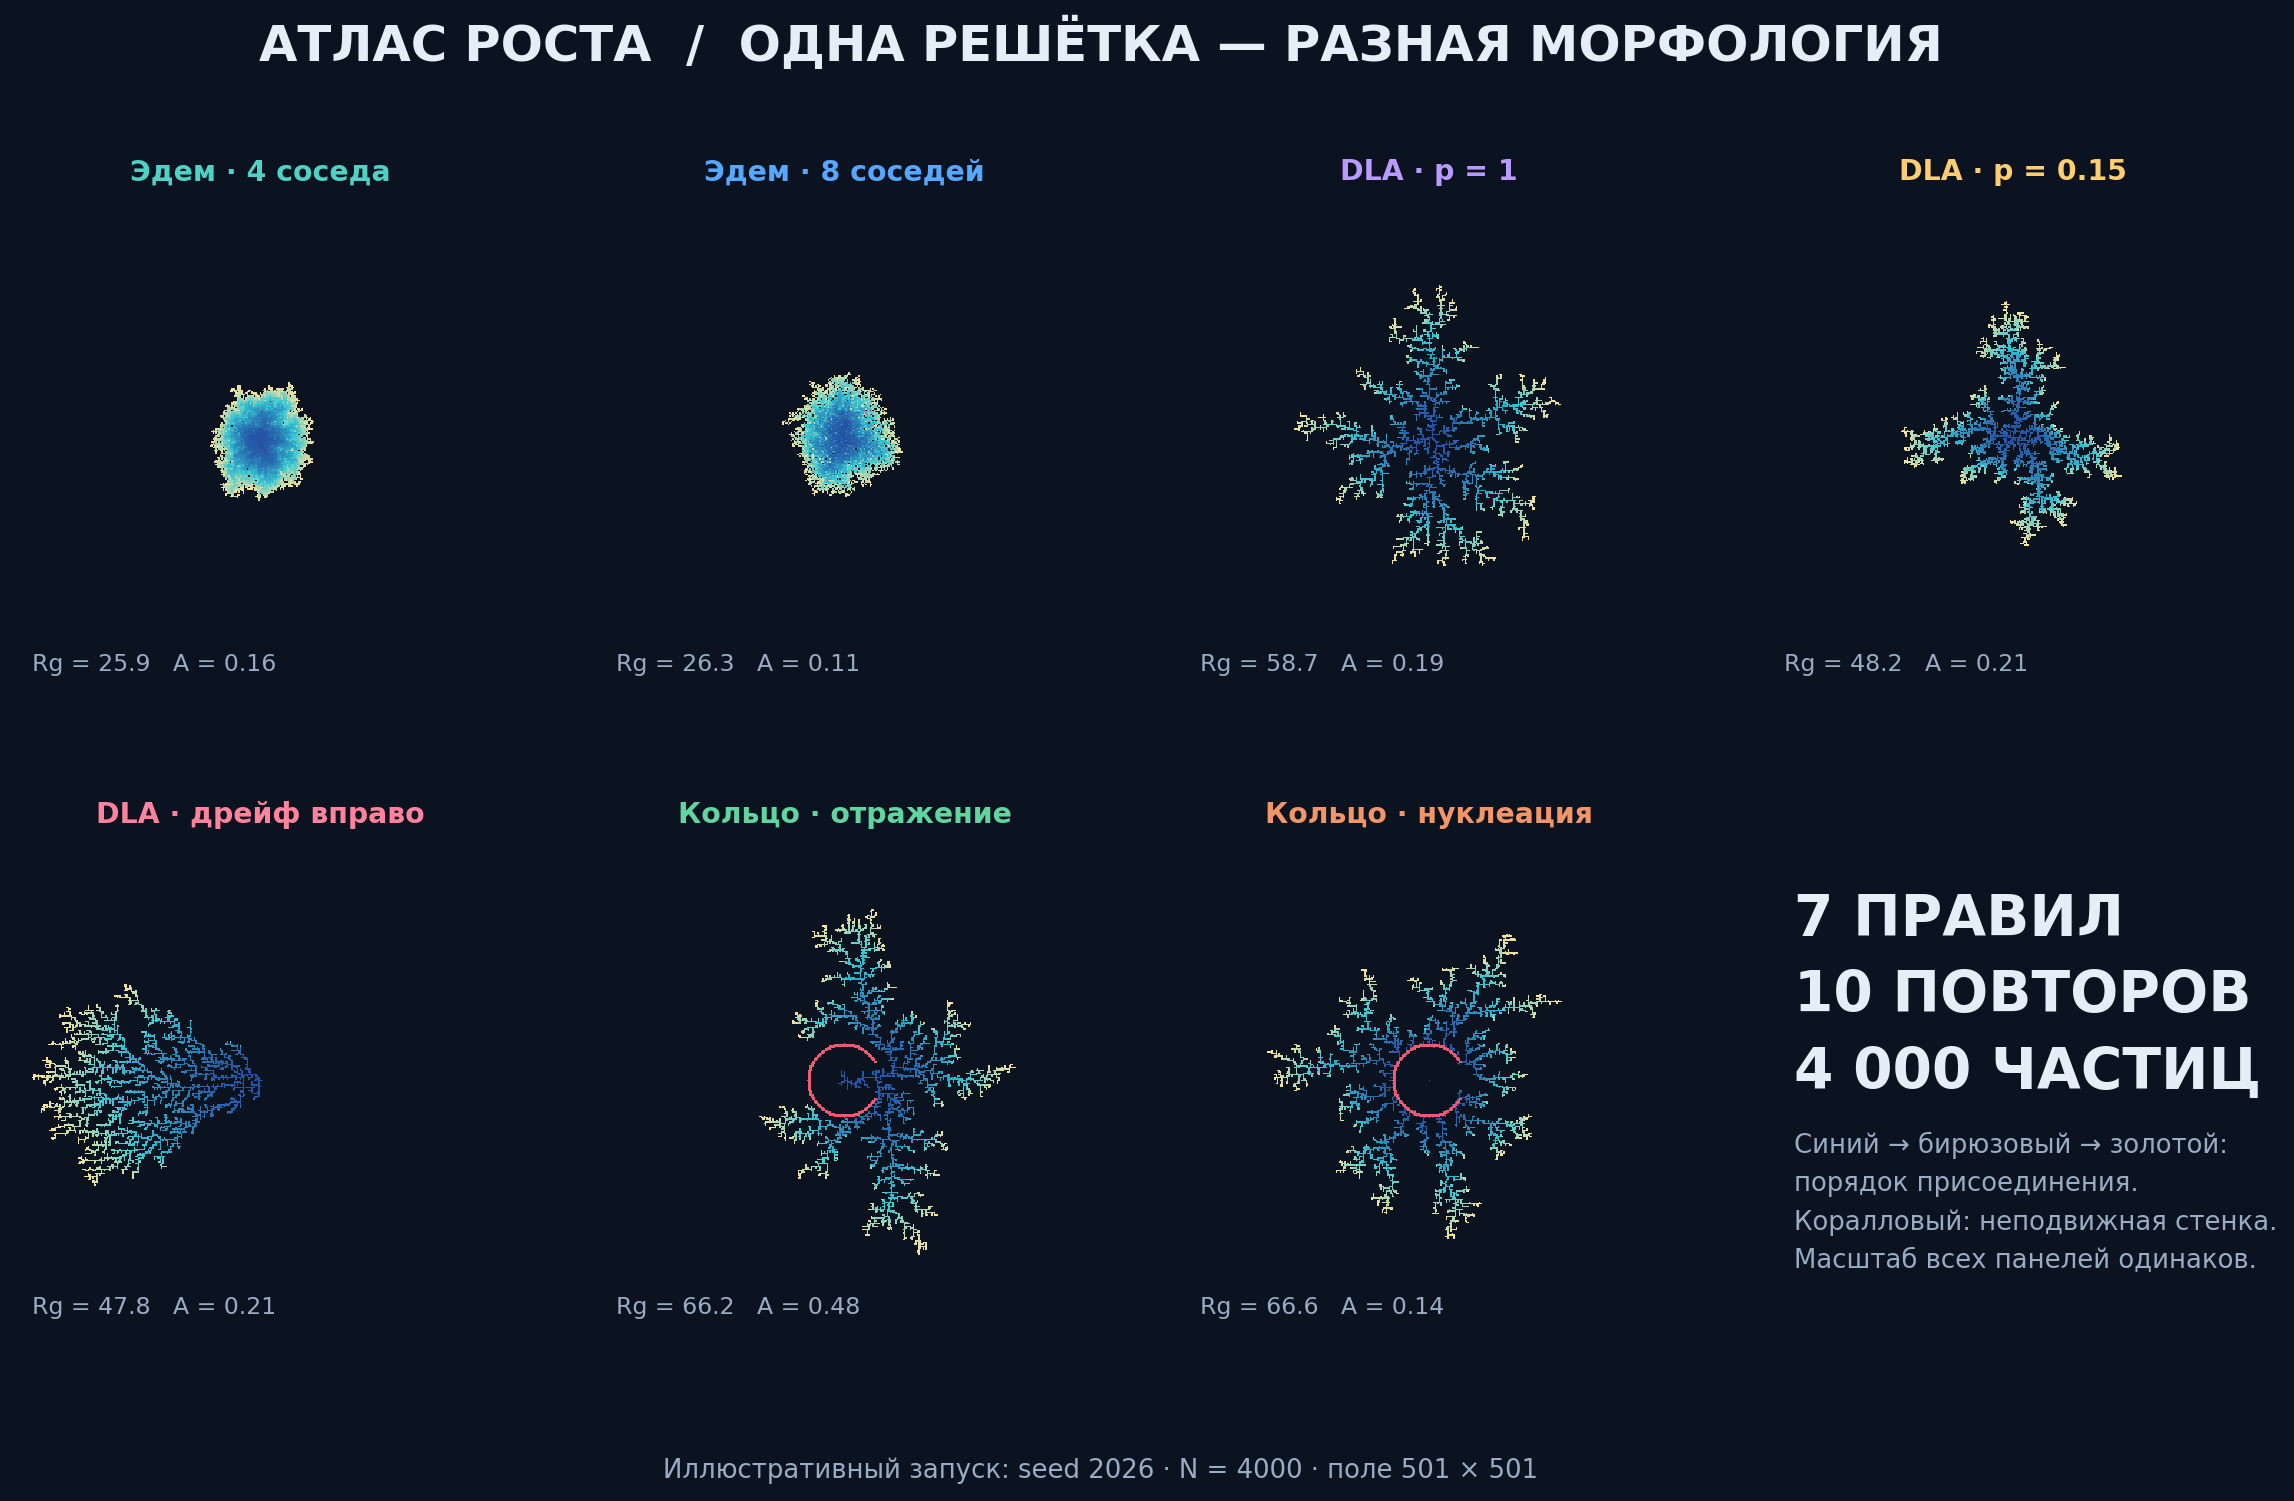

*Рисунок 2. Все семь правил при одинаковой массе и пространственном масштабе, seed = 2026. Даже при одинаковом числе частиц размер и форма кластеров существенно различаются. Стенка показана коралловым цветом. Подписи под панелями относятся к этой реализации, а не к ансамблевым средним.*



### 5.2. Сводные измерения

В таблице — **среднее ± половина 95%-го доверительного интервала**, 10 реализаций. Расстояния измеряются в клетках.

| Модель | $R_g$ | $\phi$ | $A$ | $\Delta x$ | $D_{\mathrm{eff}}$ |
|---|---:|---:|---:|---:|---:|
| Эдем, 4 соседа | 25,722 ± 0,082 | 0,630 ± 0,028 | 0,115 ± 0,039 | −0,736 ± 1,243 | 2,083 ± 0,033 |
| Эдем, 8 соседей | 26,274 ± 0,082 | 0,538 ± 0,032 | 0,117 ± 0,037 | 0,328 ± 1,682 | 2,148 ± 0,026 |
| DLA, $p=1$ | 61,878 ± 1,973 | 0,096 ± 0,013 | 0,245 ± 0,088 | 1,501 ± 4,053 | 1,691 ± 0,044 |
| DLA, $p=0{,}15$ | 45,984 ± 1,138 | 0,169 ± 0,014 | 0,235 ± 0,072 | 2,515 ± 1,136 | 1,726 ± 0,050 |
| DLA, дрейф вправо | 48,725 ± 0,659 | 0,052 ± 0,007 | 0,230 ± 0,057 | −82,304 ± 5,737 | 1,931 ± 0,059 |
| Кольцо, отражение | 65,063 ± 2,004 | 0,068 ± 0,009 | 0,319 ± 0,100 | 35,414 ± 3,610 | 1,776 ± 0,038 |
| Кольцо, нуклеация | 67,722 ± 0,880 | 0,088 ± 0,005 | 0,149 ± 0,073 | −0,548 ± 2,966 | 2,350 ± 0,039 |

Машиночитаемые данные: [каждый запуск в CSV](results/runs.csv), [полная статистика в JSON](results/summary.json), [автоматически сформированная таблица](results/tables.md).

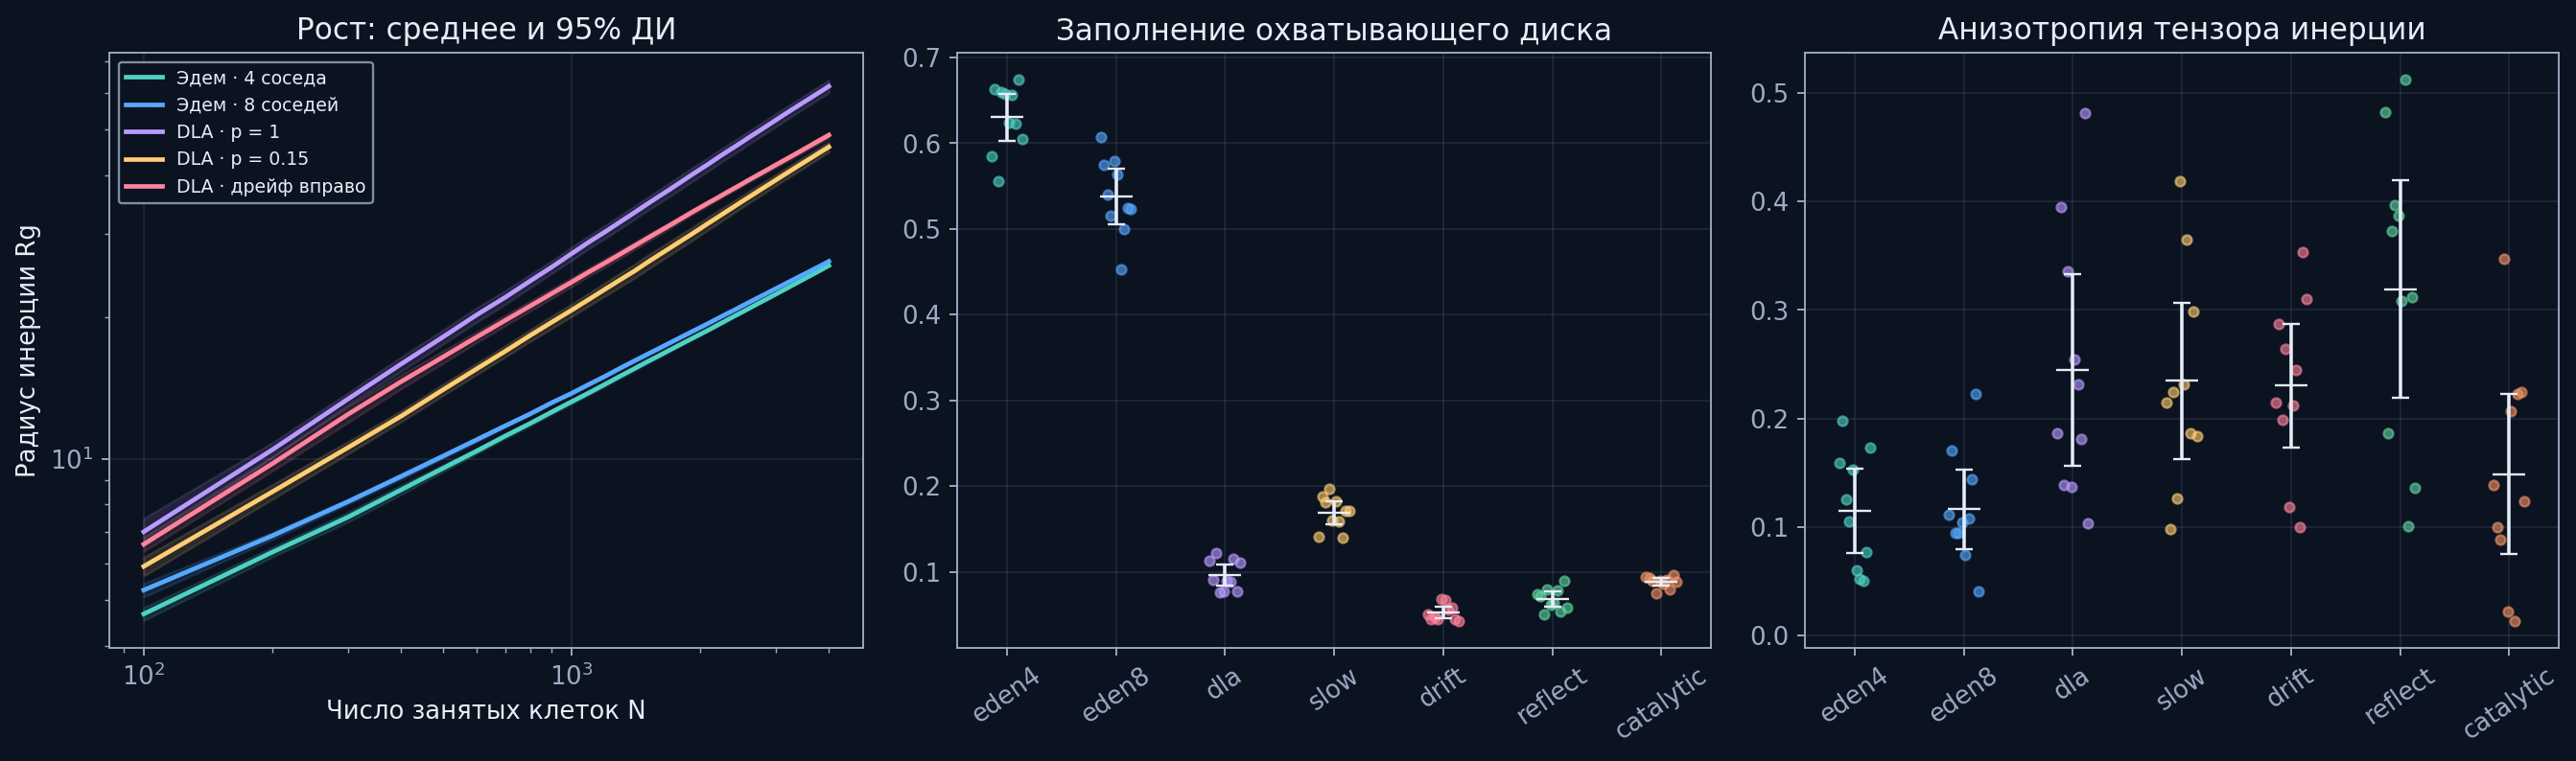

*Рисунок 3. Слева — средний радиус инерции по мере роста; цветные полосы показывают точечные 95%-е интервалы среднего. Справа — отдельные реализации, средние и интервалы итоговых характеристик. Точки одной кривой роста зависимы, поэтому полосы не являются одновременной доверительной областью всей траектории.*



### 5.3. Эдем против DLA: плотный фронт или экранирующие ветви?

В модели Эдема материал добавляется непосредственно к границе, в том числе в углублениях. В DLA вероятность достижения поверхности определяется внешним случайным блужданием: выступающие ветви перехватывают частицы, а внутренние участки экранируются.

При $N=4\,000$ средний $R_g$ базовой DLA составляет **61,88** против **25,72** у Эдема с четырьмя соседями — различие примерно в **2,41 раза**. Заполнение охватывающего диска уменьшается с **0,630** до **0,096**.

Эффективные показатели $2,083$ и $1,691$ согласуются с качественной картиной компактного и разреженного роста. Однако конечный кластер и выбранный интервал аппроксимации не позволяют объявлять эти числа точными асимптотическими размерностями.

**Итог H1:** различие механизмов отчётливо подтверждается одновременно изображениями, радиусом инерции и заполнением диска.



### 5.4. Неполное прилипание: более компактный кристалл без превращения в Эдем

При $p=0{,}15$ частица может несколько раз покинуть контактную позицию и попасть на менее доступный участок поверхности.

По ансамблевым средним:

- $R_g$ уменьшается с **61,878** до **45,984** — на **25,7%**;
- $\phi$ возрастает с **0,096** до **0,169** — в **1,76 раза**;
- показатель $D_{\mathrm{eff}}$ меняется с **1,691 ± 0,044** до **1,726 ± 0,050**.

Последние интервалы перекрываются: утверждать уверенное изменение показателя роста по этим данным нельзя. Заметное уплотнение структуры не следует автоматически называть переходом к новому фрактальному классу. Вероятность прилипания уменьшена, но транспорт по-прежнему диффузионный, а структура остаётся ветвящейся.

**Итог H2:** повышение компактности подтверждено в исследованном диапазоне; изменение асимптотической размерности и фазовый переход не доказаны.



### 5.5. Окрестность Мура не гарантирует большей округлости

В переходе от четырёх к восьми соседям средний $R_g$ увеличивается на **2,15%**, а заполнение диска уменьшается с **0,630** до **0,538**. Наличие диагональных связей позволяет расти более разреженному внешнему фронту, хотя весь кластер остаётся компактнее DLA.

Анизотропия составляет **0,115 ± 0,039** и **0,117 ± 0,037** соответственно. По этой метрике убедительного различия нет. В частности, исходное утверждение «Мур делает фронт более изотропным» нельзя повторять как установленный результат.

**Итог H5:** влияние на радиус и заполнение наблюдается; преимущество по изотропности данным измерением не подтверждено.



### 5.6. Почему кристалл растёт навстречу потоку?

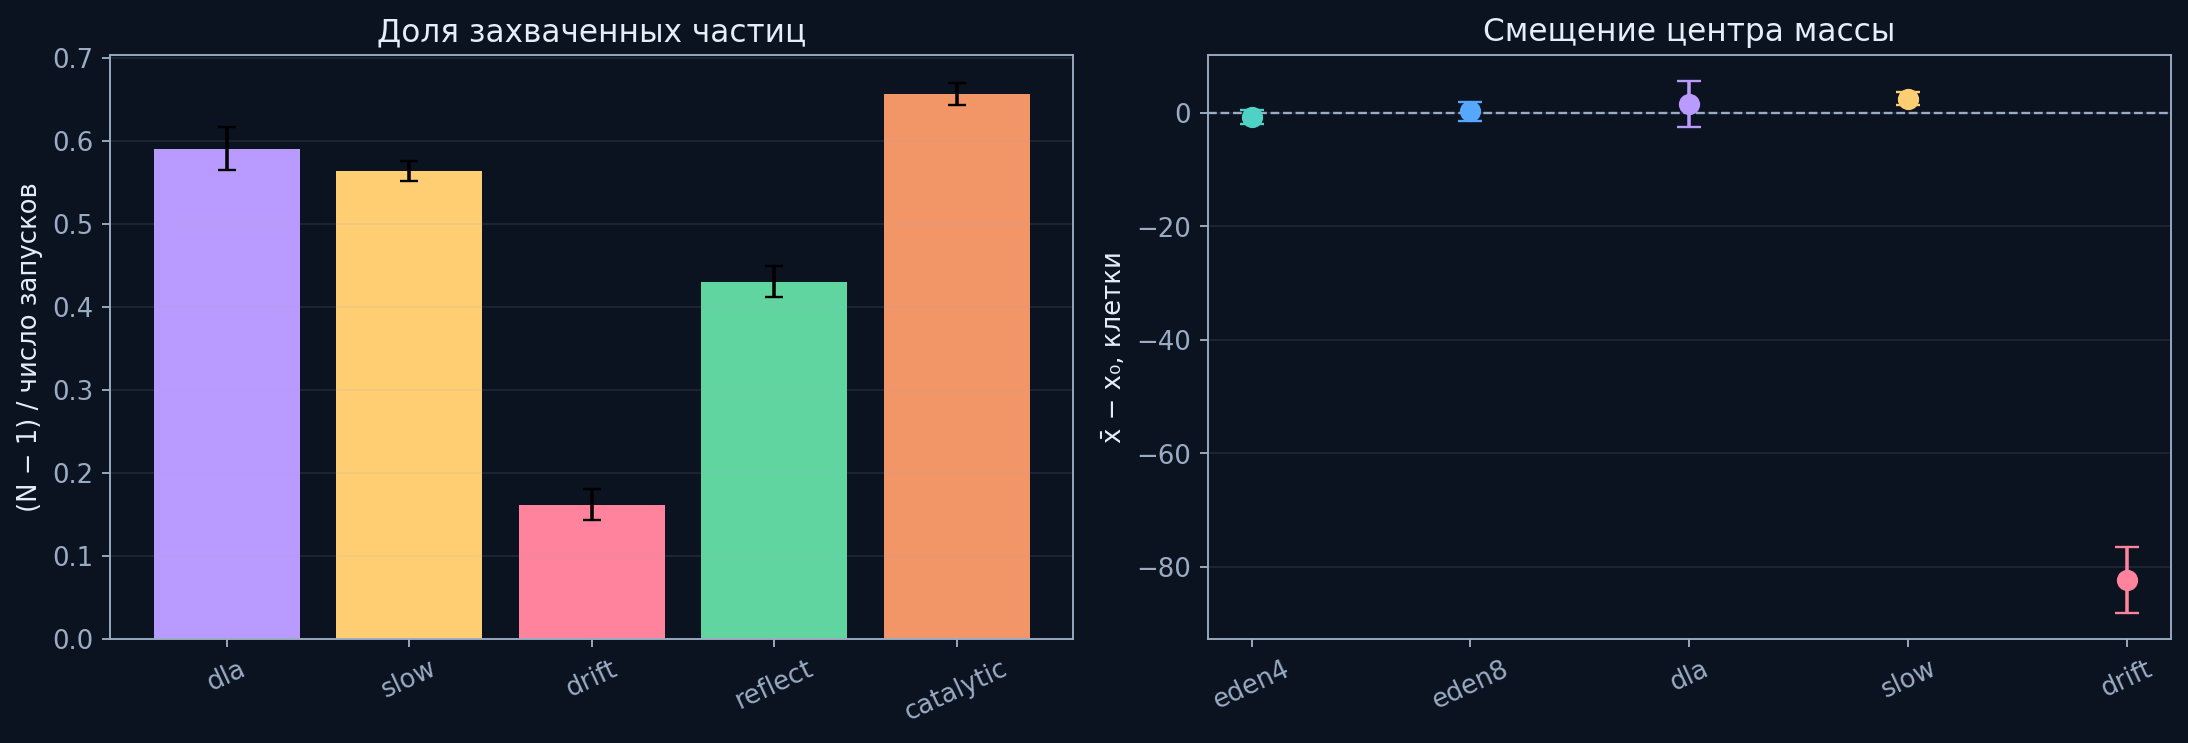

*Рисунок 4. Эффективность захвата и смещение центра массы. Столбцы и точки — ансамблевые средние, отрезки — 95%-е интервалы среднего.*

При дрейфе частиц вправо среднее смещение центра массы кристалла составляет

$$\Delta x=-82{,}30\pm5{,}74.$$

Кристалл растёт преимущественно **влево**, то есть навстречу потоку. Это не ошибка знака: частицы, запущенные слева, с большей вероятностью доходят до наветренной стороны. Частицы справа чаще уносятся от кристалла. Слева возникают преимущественные точки присоединения.

Доля захваченных частиц уменьшается с **0,590 ± 0,026** в базовой DLA до **0,162 ± 0,019** при дрейфе. Эта величина относится к конкретному источнику на окружности и правилу удаления, а не является универсальным коэффициентом осаждения.

Здесь особенно важны две разные меры размера. Радиус инерции отсчитывается от подвижного центра массы, а радиус диска — от исходной затравки. Поэтому дрейфовый кластер может иметь относительно небольшой $R_g$, но малое заполнение диска из-за большого смещения.

Анизотропия тензора в среднем не увеличилась убедительно относительно DLA. Нарушение симметрии надёжнее видно по **смещению**, а не по этой единственной метрике формы.

**Итог H3:** направленный перенос создаёт рост против потока в данном протоколе доставки частиц. Результат нельзя без проверки переносить на источник с другой геометрией.



### 5.7. Камера с отверстием: транспортный барьер или активная подложка?

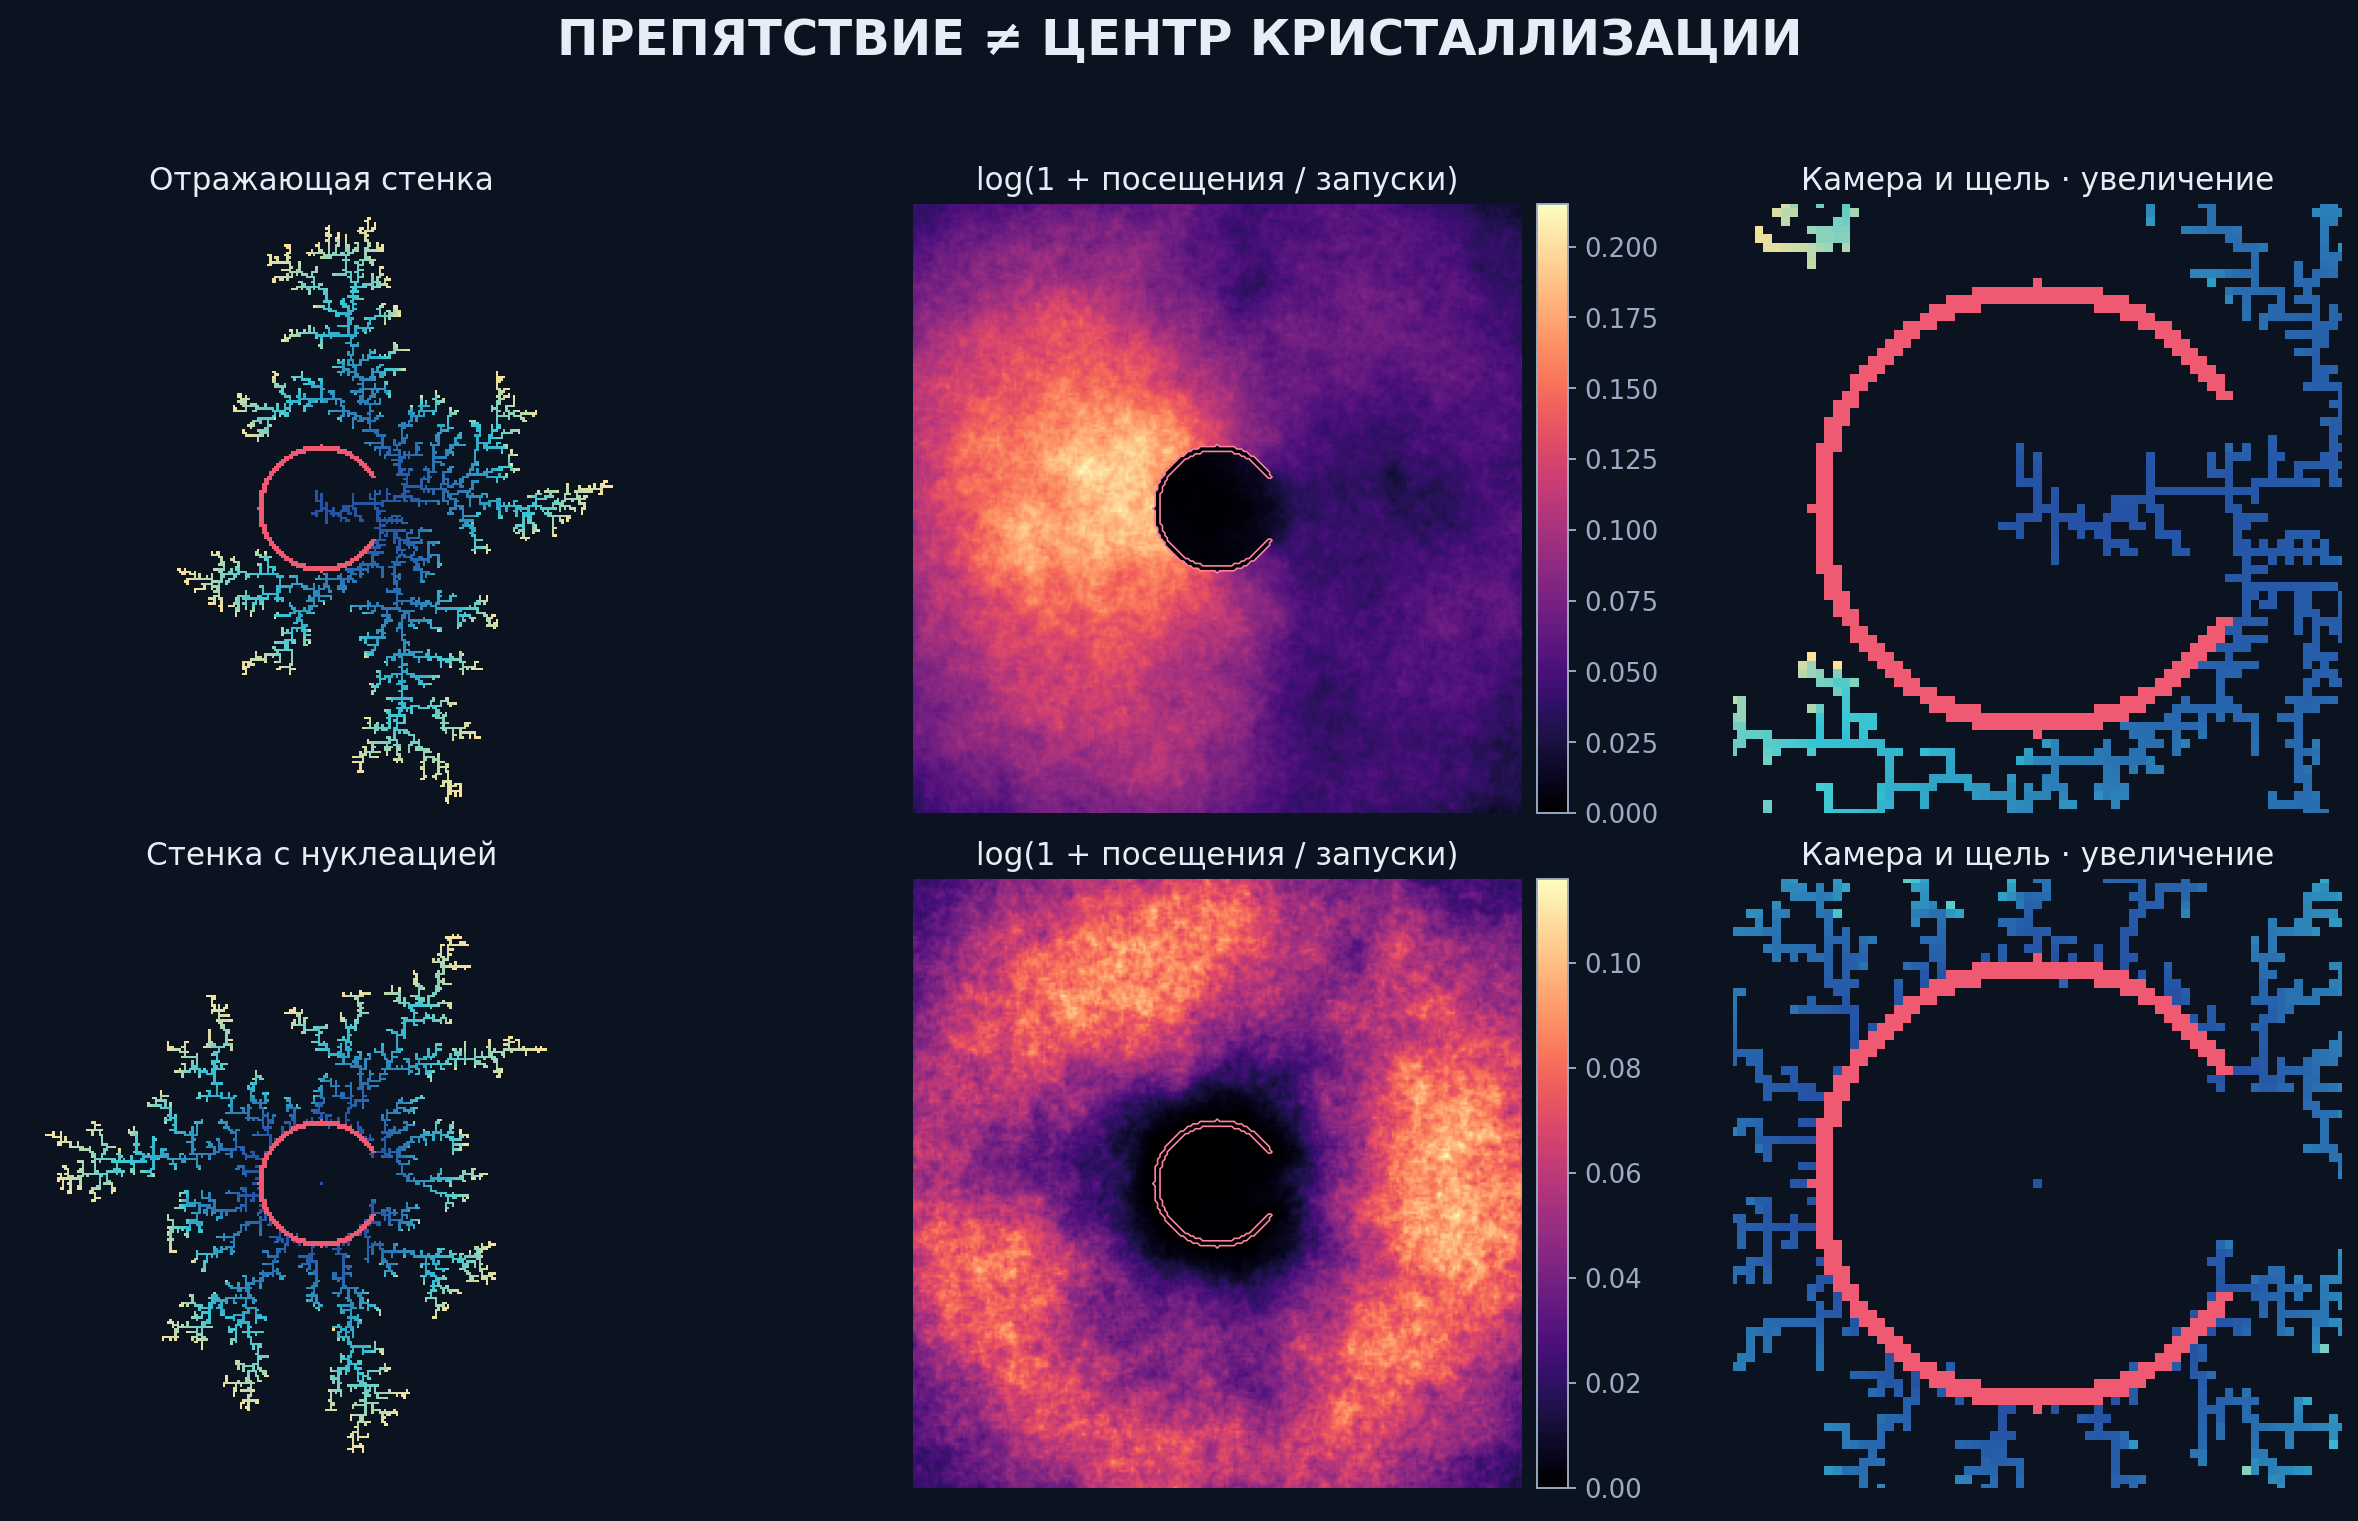

*Рисунок 5. Слева — кристалл, в центре — накопленные посещения свободных клеток на один запуск в логарифмическом представлении, справа — увеличение камеры. Две тепловые карты имеют собственные цветовые шкалы: сравнивать абсолютную яркость между строками без их учёта нельзя.*

**Отражающая стенка.** Частицы сначала должны пройти через отверстие к затравке. Возникает связный кластер, выходящий из камеры вправо. Среднее смещение центра массы — **+35,41 ± 3,61** клетки. К концу расчёта **96,38 ± 0,32%** кристаллических клеток находится за радиусом 26. Небольшое количество материала внутри камеры достаточно, чтобы сформировать канал роста; основная масса затем нарастает снаружи.

**Нуклеирующая стенка.** Рост может начаться снаружи практически по всей поверхности кольца, не дожидаясь связи с центральной затравкой. Внешняя доля массы достигает **99,57 ± 0,11%**, а среднее смещение по горизонтали близко к нулю в пределах интервала. Доля захвата выше: **0,657 ± 0,013** против **0,430 ± 0,019** у отражающей стенки.

Показатель $D_{\mathrm{eff}}=2,350$ у активной стенки особенно показателен методически. Рост стартует не из точечной геометрии, а на протяжённой подложке; поэтому его конечномасштабный наклон нельзя интерпретировать как фрактальную размерность плоского множества.

**Тепловая карта — не поле концентрации.** Она накапливается за всё время роста, пока геометрия препятствий для диффузии меняется. Это статистика посещений траекториями, показывающая затруднённую доступность камеры, но не решение стационарного уравнения диффузии и не мгновенное распределение частиц.

**Итог H4:** одинаковая непроницаемая геометрия даёт разные сценарии при смене правила прилипания к стенке. Именно физический смысл границы, а не только её рисунок, определяет результат.



<a id="6-проверка-реализации"></a>

## 6. Проверка реализации

Автоматические тесты находятся в `test_model.py`. Проверяются:

1. **Сохранение массы:** число положительных клеток равно заданному, номера присоединения образуют последовательность без пропусков и повторений.
2. **Локальная причинность:** каждая новая клетка имеет более раннего допустимого соседа либо граничит с активной подложкой.
3. **Непроницаемость стенки:** на ней нет ни кристалла, ни посещений частиц.
4. **Связность:** для четырёхсвязных моделей без нуклеации кристалл остаётся одним компонентом.
5. **Воспроизводимость:** одинаковый seed даёт одинаковый результат; другой seed меняет реализацию.
6. **Баланс частиц DLA:** запуски = присоединения + выходы + остановки по лимиту; число шагов совпадает с суммой посещений.
7. **Контроль метрик:** для симметричного квадрата заранее известны радиус инерции, нулевая анизотропия и нулевое смещение.
8. **Явные отказы:** некорректные параметры и исчерпанные лимиты не приводят к молчаливому неполному результату.

Пять тестовых методов успешно выполнены; часть из них перебирает все семь моделей. Дополнительный `verify_results.py` проверяет сохранённый комплект из 70 реализаций, пересчитывает метрики и статистику, проверяет изображения и число кадров GIF.

В 50 DLA-расчётах выполнено **545 497 запусков частиц**. Из них **62 траектории** остановлены по лимиту 100 000 шагов: 4 в базовой DLA и 58 у отражающей стенки. Это около **0,0114% запусков**, но малая доля сама по себе не доказывает нулевое смещение результатов. Эти случаи не скрывались и сохранены в CSV. Во всех 70 расчётах получена полная заданная масса.

Максимальный радиус кристалла среди всех реализаций — **171,98** клетки, тогда как половина стороны поля равна 250. Кристаллы не достигли края поля. Однако внешняя окружность удаления частиц в части расчётов ограничивается размером поля; это отдельный источник численной зависимости.



<a id="7-ограничения-исследования"></a>

## 7. Ограничения исследования

1. **Конечный масштаб.** 4 000 частиц достаточно для сравнения видимой морфологии, но недостаточно для установления асимптотических законов.
2. **Ограниченный ансамбль.** Десять seed дают оценку разброса, но не исчерпывают редкие формы. t-интервалы приближённые; строгая нормальность распределений не установлена.
3. **Численный источник и сток.** Радиусы запуска, удаления и лимит длины траектории влияют на распределение доставки. Независимое исследование сходимости по этим параметрам не выполнено.
4. **Нет фазовой диаграммы.** Рассмотрены два значения $p$ и одно ненулевое значение дрейфа. Критические параметры и фазовые переходы не определялись.
5. **Ограниченные пространственные вариации.** Исследованы две окрестности и два правила стенки, но не гексагональная решётка, периодические границы, несколько затравок или полный перебор ширины отверстия.
6. **Не все метрики измеряют одно и то же.** Заполнение диска чувствительно к смещению, а тензорная анизотропия не различает четырёхкратную симметрию и окружность.
7. **Нет физической калибровки.** Модель не содержит температуру, концентрацию раствора, поверхностную энергию, растворение и реальные единицы времени. Речь идёт об идеализированных механизмах, а не о прогнозе роста конкретного вещества.
8. **Зависимость воспроизведения от окружения.** Seed зафиксирован, но побитовая идентичность на иных версиях численных библиотек не гарантируется. Версии рабочего окружения сохранены.



<a id="8-заключение"></a>

## 8. Заключение

Выполнено воспроизводимое исследование семи вариантов стохастического роста на решётке. Новизна относительно исходной работы состоит не только в дополнительных рисунках, но и в изменении постановки вычислительного эксперимента: фиксированная реальная масса, ансамбли, доверительные интервалы и сохранение полной истории.

1. **Транспорт формирует морфологию.** DLA значительно более разрежена и пространственно протяжённа, чем модель Эдема той же массы.
2. **Вероятность закрепления управляет компактностью.** При $p=0{,}15$ радиус инерции меньше на 25,7%, заполнение диска выше в 1,76 раза; переход к новому фрактальному классу не установлен.
3. **Поток и рост могут быть противоположно направлены.** При переносе вправо преимущественное осаждение на наветренной стороне смещает кристалл влево.
4. **Свойства стенки важнее её внешнего вида.** Отражение сохраняет рост от затравки через щель, нуклеация создаёт дополнительные участки роста на подложке.
5. **Окрестность влияет на фронт, но не гарантирует изотропности.** Замена четырёх соседей восемью изменила радиус и заполнение; уменьшение тензорной анизотропии не подтверждено.
6. **Эффектная картинка не заменяет измерение.** Эффективные показатели роста и накопленные карты посещений требуют осторожной интерпретации.

Таким образом, простые локальные взаимодействия действительно порождают разнообразные глобальные структуры, но содержательный вывод о них требует контроля случайности, времени, границ и смысла используемых метрик.



<a id="9-источники-и-состав-материалов"></a>

## 9. Источники и состав материалов



### Использованные материалы

1. **«Лекция 3 — Клеточные автоматы»**, PDF из исходной папки ДЗ. Особенно разделы 3.9.1–3.9.5 о постановке экспериментов, раздел 5 о методологии и п. 6.2 о расширенном исследовании моделей роста.
2. Текущий печатный отчёт: [Кристалл.pdf](../Кристалл.pdf), [исходник LaTeX](../Кристалл.tex). Оформление соответствует лабораторной работе 2; [титульник PDF](../Титульник.pdf) и [редактируемый DOCX](../Титульник.docx) адаптированы под домашнее задание «Модель роста кристалла».
3. Программы нового исследования: `model.py`, `run.py`, `test_model.py`, `verify_results.py`.
4. Исторические материалы (старый отчёт, программы и титульный лист с реквизитами) сохранены в архиве `../../Архив_старого_ДЗ_20261123_175818.zip`, а не в рабочей папке.

Внешние источники не использовались. Все изображения в расширенной версии построены собственными расчётами; численные значения не заимствованы из справочников.



### Структура новой версии

```text
Исследование/
├── Отчёт.md              # исходный текст отчёта
├── ReadMe.ipynb          # отчёт в Markdown-ячейках со встроенными PNG/GIF
├── README.md             # визуальная галерея и инструкция
├── build_notebook.py     # сборка ноутбука из отчёта без повторного расчёта
├── model.py              # правила, измерения, план моделей
├── run.py                # 70 экспериментов и визуализация
├── test_model.py         # тесты модели
├── verify_results.py     # проверка сохранённых результатов
├── requirements.txt      # версии библиотек расчёта
└── results/
    ├── growth.gif        # 80 кадров сравнения роста
    ├── atlas.png         # общий атлас семи моделей
    ├── statistics.png    # рост, компактность, анизотропия
    ├── transport.png     # захват и направленность
    ├── walls.png         # камера и статистика посещений
    ├── runs.csv          # измерения всех 70 запусков
    ├── summary.json      # средние, SD, 95% ДИ
    ├── tables.md         # автоматически сформированная таблица
    ├── metadata.json     # параметры и окружение
    └── <модель>_<seed>.npz # 70 полных состояний
```

В каждом NPZ хранятся `birth`, `wall`, `visits`, `counters`, `mass`, `rg`. Формат читается через `numpy.load`, без загрузки pickle. Для получения состояния при массе $m$ достаточно маски `(birth > 0) & (birth <= m)`.
